# Подвиг 1

In [1]:
import torch
import torch.nn as nn

layer_nn = nn.RNN(3, 10, batch_first=True, bidirectional=True)
x = torch.rand(8, 7, 3)
a, b = layer_nn(x)

In [2]:
a.shape

torch.Size([8, 7, 20])

In [3]:
b.shape

torch.Size([2, 8, 10])

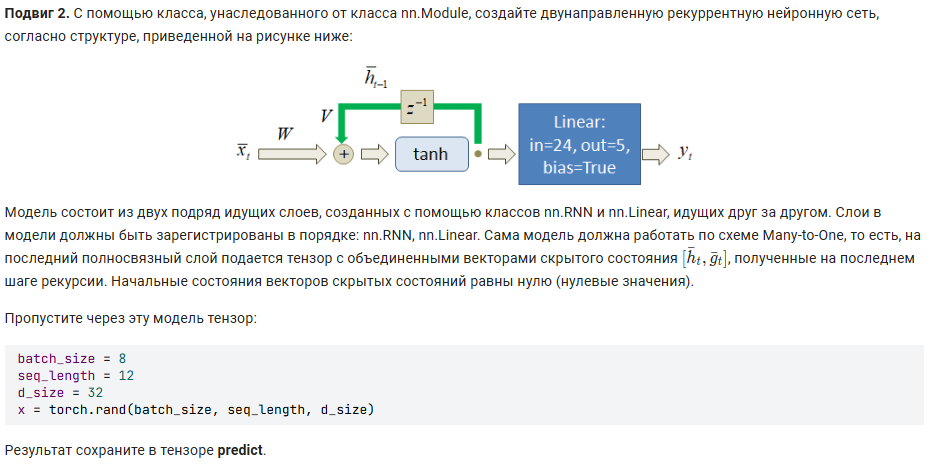

In [4]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyNet(nn.Module):
    def __init__(self, input_size, linear_input):
        super().__init__()
        self.rnn = nn.RNN(input_size, int(linear_input/2), batch_first=True, bidirectional=True, nonlinearity='tanh')
        self.linear = nn.Linear(linear_input, 5, bias=True)

    def forward(self, x):
        y, h = self.rnn(x)
        # print(h.shape)
        # print(y[:, -1, :] == torch.cat([h[0], h[1]], dim=1))
        # h = h.reshape(1, 8, -1).squeeze(0)
        # print(h.shape)
        # print(h.reshape(1, 8, -1).squeeze(0).shape)
        # print(torch.cat([h[0], h[1]], dim=1).shape)
        h = torch.cat([h[0], h[1]], dim=1)
        h = y[:, -1, :]
        out = self.linear(h)
        return out

batch_size = 8
seq_length = 12
d_size = 32
x = torch.rand(batch_size, seq_length, d_size)

model = MyNet(input_size=d_size, linear_input=24) # создание объекта модели

# здесь продолжайте программу
model.eval()
predict = model(x)
predict

tensor([[ 0.2479, -0.0162, -0.0314, -0.3359,  0.0789],
        [-0.0421, -0.0353, -0.1140, -0.0975, -0.0008],
        [ 0.1813, -0.1235, -0.0956, -0.1793,  0.3419],
        [ 0.0106, -0.0954, -0.2728, -0.1512,  0.1033],
        [-0.0665, -0.0202, -0.1999, -0.1093,  0.1277],
        [ 0.1749,  0.0726, -0.1690, -0.1959,  0.2150],
        [-0.0061, -0.1678, -0.1492, -0.4188,  0.0886],
        [ 0.1291,  0.0452, -0.1044, -0.1556,  0.1749]],
       grad_fn=<AddmmBackward0>)

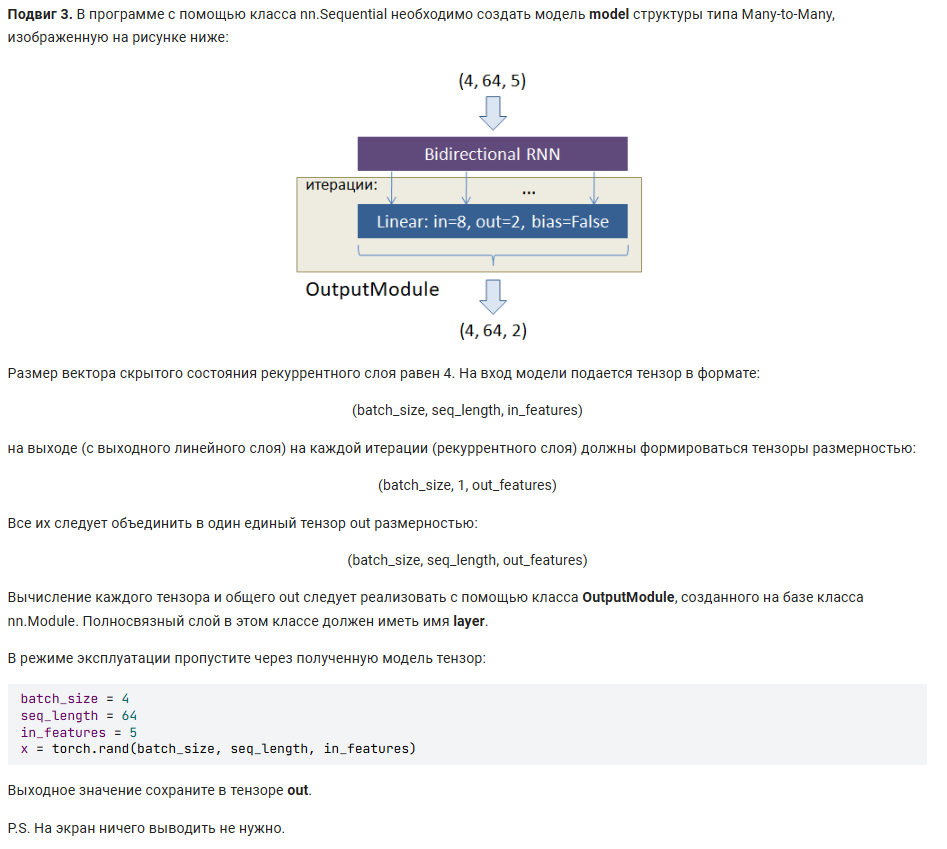

Тут имеется в виду, что в экземпляр класса OutputModule должен поступать выход слоя RNN

In [9]:
import torch
import torch.nn as nn

# здесь объявляйте класс OutputModule

# тензор x в программе не менять
batch_size = 4
seq_length = 64
in_features = 5
x = torch.rand(batch_size, seq_length, in_features)


class OutputModule(nn.Module):
    def __init__(self, input_size, input_linear):
        super().__init__()
        self.rnn = nn.RNN(input_size, int(input_linear/2), batch_first=True, bidirectional=True)
        self.layer = nn.Linear(input_linear, 2, bias=False)
        

    def forward(self, x):
        out = []
        for i in range(x.shape[1]):
            _, h = self.rnn(x[:, i, :].unsqueeze(1))
            h = torch.cat([h[0], h[1]], dim=1)
            res = self.layer(h)
            out.append(res)
        out = torch.stack(out, dim=1)
        print(out.shape)
        return out


model = OutputModule(input_size=in_features, input_linear=8)
model(x)

# model = nn.Sequential(
#     nn.RNN(input_size=5, hidden_size=4, batch_first=True, bidirectional=True),
#     nn.Linear(8, 2, bias=False)
    
# ) # создание объекта модели

# здесь продолжайте программу

torch.Size([4, 64, 2])


tensor([[[-0.2382, -0.0925],
         [ 0.0627,  0.0304],
         [ 0.0899,  0.0335],
         [-0.0924, -0.0376],
         [ 0.0789,  0.0453],
         [-0.0353, -0.0878],
         [ 0.1326,  0.0715],
         [-0.1029, -0.0350],
         [-0.1637, -0.0027],
         [-0.0418, -0.0644],
         [-0.0191, -0.0394],
         [-0.1163, -0.0647],
         [-0.2167, -0.0188],
         [-0.1484,  0.0428],
         [-0.0140, -0.0855],
         [ 0.0068,  0.0778],
         [-0.1717,  0.0169],
         [-0.2191, -0.0674],
         [-0.1327,  0.0327],
         [-0.0775,  0.0518],
         [-0.2144, -0.0793],
         [ 0.0244,  0.1226],
         [-0.0221, -0.0400],
         [-0.1375, -0.1147],
         [-0.0135,  0.0028],
         [-0.1601, -0.0178],
         [ 0.0444,  0.0996],
         [-0.2464,  0.0133],
         [-0.1149,  0.0106],
         [ 0.0050,  0.0246],
         [-0.0501, -0.0389],
         [-0.0757, -0.1375],
         [-0.1504, -0.0820],
         [-0.0294, -0.0006],
         [-0.1

In [14]:
import torch
import torch.nn as nn

# здесь объявляйте класс OutputModule
class OutputModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(8, 2, bias=False)

    def forward(self, x):
        # x - это то что пришло с итерации RNN (y, h)
        batch_size = x[0].shape[0]   # 4
        seq_length = x[0].shape[1]   # 64
        
        out = []
        for i in range(seq_length):
            out.append(self.layer(x[0][:, i, :]))
        out = torch.stack(out, dim=1)
        return out



# тензор x в программе не менять
batch_size = 4
seq_length = 64
in_features = 5
x = torch.rand(batch_size, seq_length, in_features)

model = nn.Sequential(
    nn.RNN(input_size=5, hidden_size=4, batch_first=True, bidirectional=True),
    OutputModule()
)

# здесь продолжайте программу
model.eval()
out = model(x)
out

tensor([[[-3.3833e-01, -1.8403e-01],
         [-2.7343e-01,  2.2669e-04],
         [-7.0859e-02,  1.5299e-01],
         [-3.6369e-01, -4.3761e-02],
         [-3.3749e-01,  4.0539e-02],
         [-2.1809e-01,  7.9227e-02],
         [-1.5799e-01,  2.0432e-01],
         [-1.2795e-01,  2.6336e-01],
         [-3.1677e-01, -7.6189e-02],
         [-3.4323e-01, -1.9589e-01],
         [-1.3699e-01,  3.2199e-02],
         [-5.6780e-03,  1.6401e-01],
         [-1.3022e-01,  1.0247e-01],
         [-2.0999e-01,  1.9870e-01],
         [-3.6711e-01, -2.1862e-01],
         [-1.6004e-01,  1.1192e-01],
         [-1.3647e-01,  2.3188e-01],
         [-2.9398e-01,  2.7243e-02],
         [-3.0242e-01,  1.1526e-01],
         [-2.3913e-01, -1.2866e-02],
         [-1.3643e-01,  1.9920e-01],
         [-9.2447e-02,  8.2814e-02],
         [-1.6275e-01,  9.6570e-02],
         [-2.8000e-01,  1.6704e-01],
         [-2.9061e-01,  4.2248e-03],
         [-4.4794e-02,  3.1274e-01],
         [-2.6990e-01,  1.0584e-01],
 

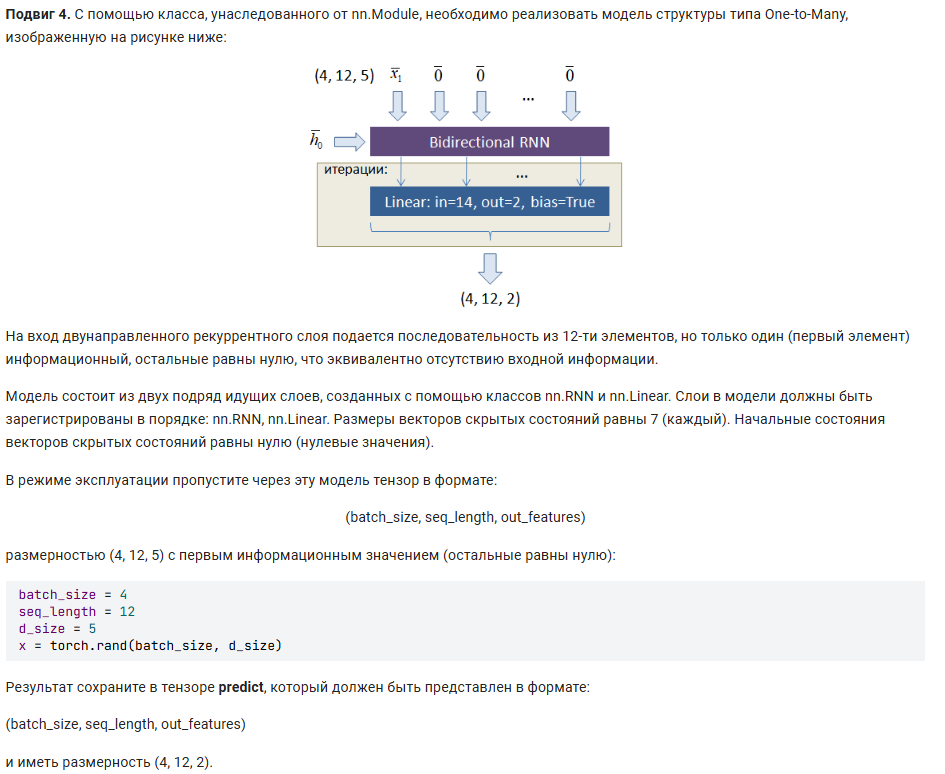

In [28]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(5, 7, batch_first=True, bidirectional=True)
        self.linear = nn.Linear(14, 2, bias=True)

    def forward(self, x):
        y, _ = self.rnn(x) # batch_size, seq_length, hidden_size
        seq_length = y.shape[1]

        out = []
        for i in range(seq_length):
            out.append(self.linear(y[:, i, :]))

        return torch.stack(out, dim=1)

# тензор x в программе не менять
batch_size = 4
seq_length = 12
d_size = 5
x = torch.rand(batch_size, d_size)
inp = torch.zeros(batch_size, seq_length, d_size)
inp[:, 0, :] = x

model = MyModel() # создание объекта модели
model.eval()
predict = model(inp)

# здесь продолжайте программу
predict

tensor([[[-0.0965,  0.2211],
         [ 0.2436, -0.0883],
         [ 0.2470, -0.1853],
         [ 0.2061, -0.1597],
         [ 0.1732, -0.1726],
         [ 0.1814, -0.1351],
         [ 0.1689, -0.1476],
         [ 0.1910, -0.1291],
         [ 0.1652, -0.1419],
         [ 0.2012, -0.1150],
         [ 0.1754, -0.1758],
         [ 0.2287, -0.1889]],

        [[ 0.0744,  0.3108],
         [ 0.2676, -0.1464],
         [ 0.2546, -0.1540],
         [ 0.2028, -0.1866],
         [ 0.1745, -0.1535],
         [ 0.1802, -0.1447],
         [ 0.1705, -0.1394],
         [ 0.1909, -0.1334],
         [ 0.1659, -0.1389],
         [ 0.2011, -0.1170],
         [ 0.1756, -0.1746],
         [ 0.2286, -0.1897]],

        [[ 0.1394,  0.2367],
         [ 0.2213, -0.1508],
         [ 0.2338, -0.1320],
         [ 0.1997, -0.1847],
         [ 0.1769, -0.1484],
         [ 0.1812, -0.1482],
         [ 0.1710, -0.1390],
         [ 0.1906, -0.1351],
         [ 0.1658, -0.1385],
         [ 0.2008, -0.1174],
         [

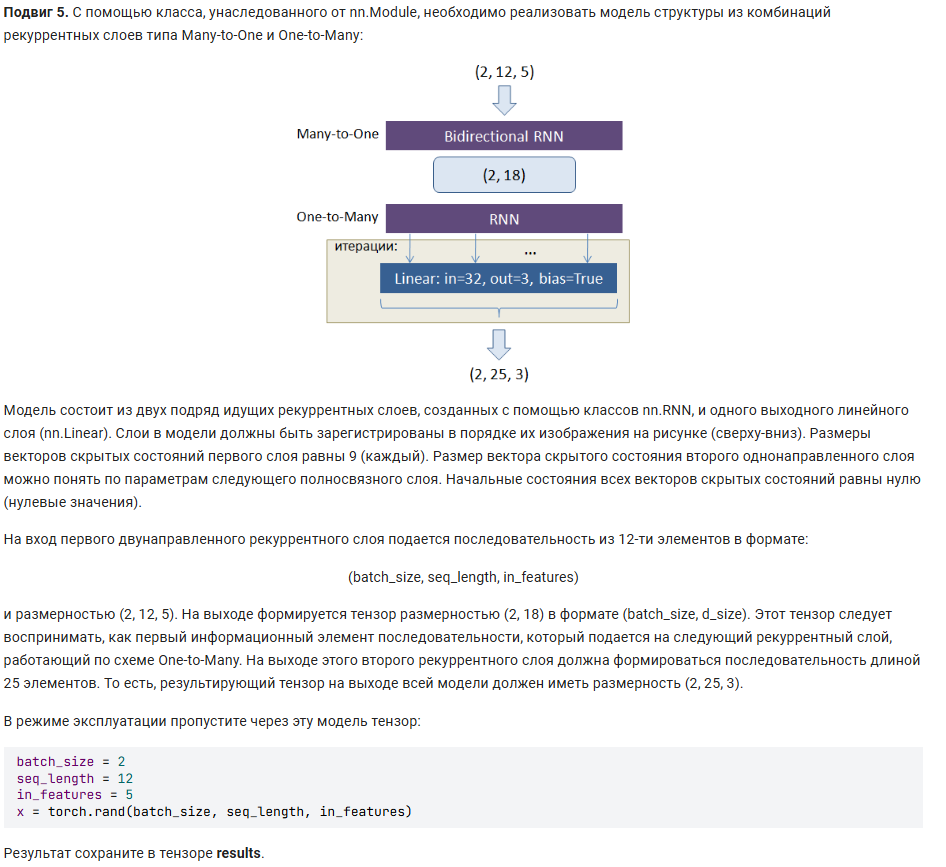

In [42]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn1 = nn.RNN(5, 9, batch_first=True, bidirectional=True)
        self.rnn2 = nn.RNN(18, 32, batch_first=True, bidirectional=False)
        self.linear = nn.Linear(32, 3, bias=True)

    def forward(self, x):
        bs = x.shape[0]
        
        _, h = self.rnn1(x) 
        print(h.shape)
        # h = h.reshape(x.shape[0], -1) # [2, 18]
        h = torch.cat([h[0, :, :], h[1, :, :]], dim=1)
        print(h.shape)

        seq_length = 25
        x = torch.zeros(bs, seq_length, h.shape[1]) # [2, 25, 18]
        x[:, 0, :] = h
        y, _ = self.rnn2(x)

        out = []
        for i in range(seq_length):
            out.append(self.linear(y[:, i, :]))
        out = torch.stack(out, dim=1)
        return out


# тензор x в программе не менять
batch_size = 2
seq_length = 12
in_features = 5
x = torch.rand(batch_size, seq_length, in_features)

model = MyNet() # создание объекта модели
model.eval()

results = model(x)
results.shape
# здесь продолжайте программу

torch.Size([2, 2, 9])
torch.Size([2, 18])
torch.Size([2, 25, 3])


torch.Size([2, 25, 3])

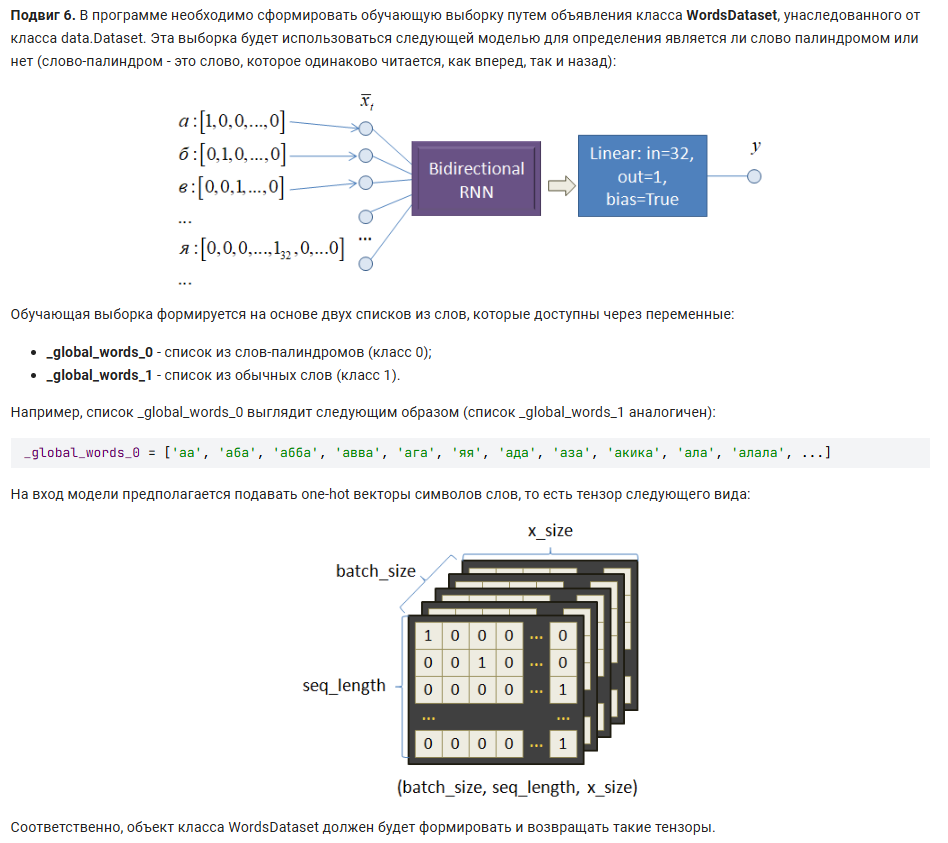

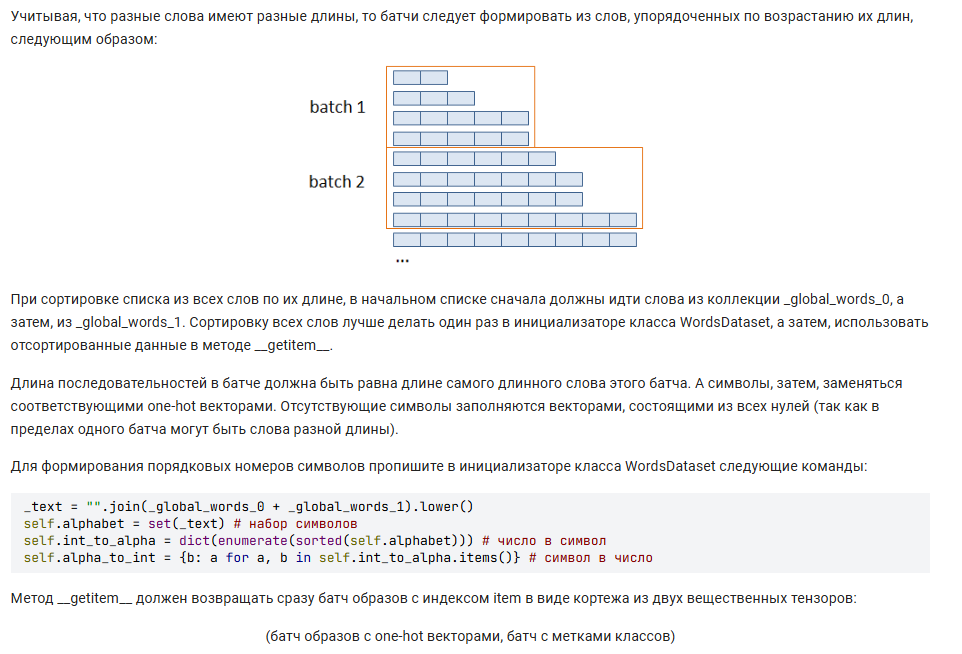

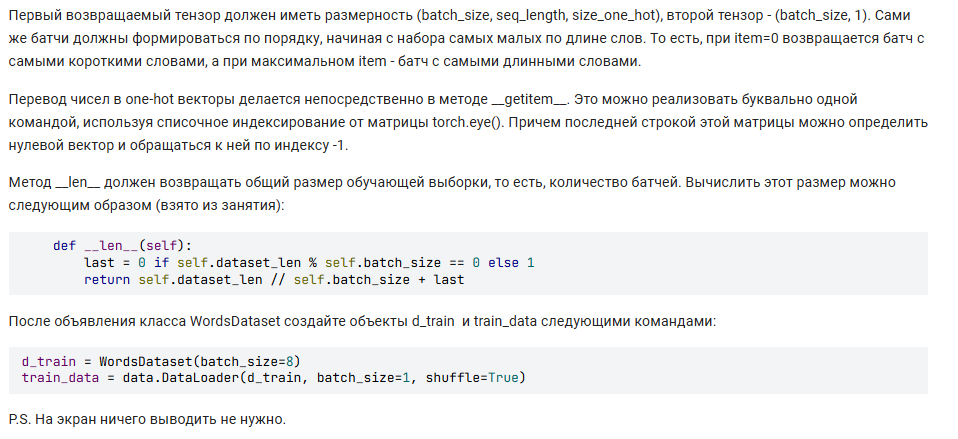

In [204]:
import torch
import torch.nn as nn
import torch.utils.data as data

_global_words_0 = ['аа', 'аатаа', 'аба', 'абиба', 'ава', 'аваава', 'авава', 'авва', 'ага', 'агга', 'ада', 'адда', 'ажа', 'ака', 'акака', 'аканака', 'акика', 'акка', 'ала', 'алала', 'алафала', 'амакама', 'амма', 'ана', 'анапана', 'анасана', 'анатана', 'анисина', 'анна', 'анона', 'апа', 'апипа', 'аппа', 'ара', 'арара', 'арора', 'арра', 'арура', 'аса', 'ата', 'атета', 'атта', 'аулуа', 'афа', 'аха', 'ахаха', 'ахоха', 'ахха', 'аца', 'ацыца', 'ача', 'аша', 'баб', 'бараб', 'батаб', 'бахаб', 'биб', 'боб', 'вёв', 'вив', 'вызыв', 'гачаг', 'гег', 'гиг', 'гириг', 'гог', 'гыг', 'гэг', 'дед', 'дид', 'диороид', 'довод', 'дойод', 'дород', 'доход', 'дуд', 'еае', 'ейе', 'ёре', 'ере', 'ёте', 'жож', 'заказ', 'замаз', 'заз', 'зуз', 'чи', 'и', 'иааи', 'иаи', 'иби', 'иви', 'идииди', 'ижжи', 'изи', 'ики', 'или', 'илли', 'иньни', 'ири', 'ирори', 'ихи', 'ичи', 'ичиичи', 'ишши', 'йай', 'йой', 'каак', 'кабак', 'кавак', 'казак', 'кайак', 'как', 'канак', 'капак', 'карак', 'касак', 'кассак', 'кек', 'кёк', 'келек', 'келлек', 'керек', 'кесек', 'кечёк', 'кибик', 'кижик', 'кизик', 'киик', 'кийик', 'кик', 'килик', 'киллилиллик', 'киник', 'киноник', 'кичик', 'кишик', 'ковок', 'кок', 'коллок', 'колок', 'комок', 'конок', 'копок', 'коппок', 'корок', 'косок', 'кошок', 'кудук', 'кук', 'кумук', 'курук', 'куук', 'кыйык', 'кык', 'кытык', 'кэк', 'кюк', 'лаал', 'лал', 'лобол', 'лол', 'лыл', 'мадам', 'мазам', 'макам', 'мам', 'манам', 'марам', 'мелем', 'мем', 'мивим', 'мидим', 'миллим', 'мим', 'миним', 'мом', 'моном', 'мум', 'мурум', 'мэм', 'наан', 'набан', 'наган', 'назан', 'накан', 'нан', 'напан', 'насан', 'нашан', 'некен', 'нен', 'ненен', 'нигин', 'нимин', 'нойон', 'нон', 'ноон', 'норурон', 'нэн', 'нян', 'о', 'обибо', 'обо', 'ово', 'оддо', 'ойо', 'око', 'оло', 'ололо', 'оно', 'оо', 'оро', 'ороборо', 'оруро', 'оссо', 'офо', 'очо', 'ошо', 'переп', 'покоп', 'поп', 'посоп', 'потоп', 'пуп', 'радар', 'расар', 'ревер', 'реер', 'рейер', 'ремер', 'репер', 'реппер', 'рер', 'рогор', 'ророр', 'ротатор', 'ротор', 'рэпєр', 'рэппєр', 'сас', 'секес', 'сиис', 'солос', 'соссос', 'статс', 'суккус', 'сукус', 'сус', 'таат', 'такат', 'таннат', 'тартрат', 'тассат', 'тат', 'тауат', 'тидит', 'тиллит', 'тимит', 'тирит', 'тит', 'тихит', 'тозот', 'топот', 'торот', 'тумут', 'тут', 'тыыт', 'у', 'убу', 'уду', 'улу', 'уруушу', 'фараф', 'феф', 'ханнах', 'хенех', 'хох', 'целец', 'чаач', 'чабач', 'чавач', 'чагач', 'чепеч', 'чеч', 'чижич', 'шабаш', 'шалаш', 'шамаш', 'шараш', 'шереш', 'шириш', 'шиш', 'шош', 'шугуш', 'шумуш', 'щэщ', 'эвэ', 'эдэ']
_global_words_1 = ['сарпиночник', 'контрабандист', 'мопед', 'вульгарность', 'ятрышник', 'следопыт', 'оперирование', 'шпажист', 'англосаксонец', 'натуралистичность', 'серница', 'раздел', 'памятник', 'антрополог', 'новорождённая', 'окрол', 'гальваноскоп', 'кофта', 'председатель', 'ржанище', 'помилованная', 'примирение', 'суберин', 'папуаска', 'злободневность', 'эпископ', 'неучтивость', 'адат', 'подавание', 'походка', 'хорь', 'брейд-вымпел', 'предпочтение', 'слепушонок', 'кудель', 'эдикт', 'разнеженность', 'духанщик', 'вертолётчица', 'светотехника', 'провозгласитель', 'бериллий', 'пискунья', 'отгонщик', 'глиптодонт', 'локомобиль', 'пресмыкание', 'старобытность', 'двупланность', 'лютеций', 'прирез', 'рявкание', 'перегрузка', 'токсиколог', 'искусительница', 'дикция', 'древность', 'сертификация', 'магистраль', 'фагоцитоз', 'всесторонность', 'армада', 'люэс', 'бутоньерка', 'полустишие', 'сельхозинвентарь', 'огранка', 'минускул', 'монотипист', 'дань', 'бармен', 'выпирание', 'противосияние', 'альтист', 'бекас', 'глиптотека', 'полиграфия', 'уменьшение', 'лункование', 'клирос', 'пагода', 'элементарность', 'предпочтительность', 'горицвет', 'ксилофон', 'игиль', 'паратость', 'ножовщик', 'гель', 'непроизносимость', 'отшвыривание', 'новолуние', 'обрезок', 'технеций', 'самбист', 'инсулин', 'бирманка', 'гвардия', 'папуас', 'оживание', 'заскабливание', 'переливт', 'кройка', 'контроверза', 'ниспровержение', 'нагреватель', 'плата', 'паралитик', 'платан', 'эндокард', 'скликание', 'инвенция', 'раскутывание', 'загустение', 'чека', 'перенагревание', 'припыл', 'тенётчик', 'натюрморист', 'цивилизованность', 'упрощение', 'отопленец', 'свечка', 'предплужник', 'юродивая', 'неприличность', 'вех', 'лежание', 'драчливость', 'фидеист', 'дезодорант', 'прокапчивание', 'сбережение', 'посыльная', 'фольклористика', 'вдохновитель', 'культурница', 'виноградарь', 'пряничник', 'практикант', 'тузлук', 'плач', 'вареник', 'рислинг', 'транш', 'укупорщик', 'усложнение', 'фальшивомонетничество', 'пышность', 'подстановка', 'санитар', 'линовальщик', 'септик', 'пережидание', 'фалл', 'наивность', 'метафизичность', 'вычищение', 'лярд', 'передрессировывание', 'долгожитель', 'метрополитен', 'прошивка', 'подчитывание', 'ёлка', 'подкрутка', 'аил', 'концепция', 'обмол', 'обиженная', 'жертвенник', 'отчизна', 'шёпот', 'обмыливание', 'водохранилище', 'пантовар', 'притачка', 'кардиография', 'навинчивание', 'угнетённость', 'высокопарность', 'ломаная', 'непоследовательность', 'дилетант', 'разгром', 'горло', 'коалиция', 'федералист', 'отдыхающий', 'неудовлетворительность', 'театральность', 'шурфование', 'подгрузка', 'привкус', 'крольчатина', 'ярка', 'декабристка', 'неоклассик', 'откус', 'педфак', 'одежда', 'евпатория', 'индонезия', 'кастрюля', 'качели', 'мамонт', 'копье', 'колледж', 'авиаметеостанция', 'гороскоп', 'марево', 'десница', 'мозоль', 'копоть', 'креветка', 'качалка', 'конвейер', 'алоэ', 'камбуз', 'катализатор', 'ладонь', 'крыло', 'кий', 'амфибия', 'бородавка', 'кафтан', 'стул', 'иордания', 'электричка', 'пещера', 'мундир', 'водоросль', 'бар', 'балерина', 'граната', 'брус', 'купальня', 'башмачок', 'берлин', 'жеребец', 'воробей', 'сова', 'леденец', 'арена', 'узел', 'софа', 'утюг', 'ландыш', 'вакцина', 'бурьян', 'погреб', 'душ', 'гамбург', 'джунгли', 'голень', 'желток', 'лохмотья', 'берег', 'голгофа', 'шкатулка', 'венок', 'малыш', 'кемпинг', 'паркет', 'баня', 'департамент', 'боекомплект', 'канзас', 'дренаж', 'капсула', 'автомагистраль', 'антиквар', 'мотор', 'карамелька', 'лев', 'впадина', 'декада', 'масленка', 'медпункт', 'мультфильм', 'лотерея', 'калория', 'говядина', 'камфара', 'зубок', 'лимузин', 'бильярд', 'колдобина', 'иероглиф', 'воск', 'шпаргалка', 'траншея', 'авиастроитель', 'пряник', 'бром', 'автопоезд', 'кортик', 'дыхание', 'империя', 'плов']

class WordsDataset(data.Dataset):
    def __init__(self, batch_size=8):
        super().__init__()
        self.batch_size = batch_size

        data = [(word, 0) for word in _global_words_0] + [(word, 1) for word in _global_words_1]
        data.sort(key=lambda x: len(x[0]))

        self.batches = len(data) // self.batch_size

        self.words = [item[0] for item in data]
        self.labels = torch.tensor([item[1] for item in data], dtype=torch.float32)

        _text = "".join(_global_words_0 + _global_words_1).lower()
        self.alphabet = set(_text) # набор символов
        self.int_to_alpha = dict(enumerate(sorted(self.alphabet))) # число в символ
        self.zero_symbol = "@"
        
        self.int_to_alpha[len(self.int_to_alpha)] = self.zero_symbol # вводим вспомогательный символ
        self.alpha_to_int = {b: a for a, b in self.int_to_alpha.items()} # символ в число

        self.onehot = torch.eye(len(self.alphabet))
        self.onehot = torch.nn.functional.pad(self.onehot, (0, 0, 0, 1)) # последняя строка теперь нулевой вектор
    

    def __getitem__(self, item): # формирование и возвращение батча данных по индексу item
        
        start = item * self.batch_size
        end = start + self.batch_size

        batch = self.words[start: end]
        batch_longest_word_length = len(batch[-1])
        one_hot_words = []
        
        for word in batch:
            word += (batch_longest_word_length - len(word)) * self.zero_symbol
            one_hot_word = [self.onehot[self.alpha_to_int[letter]] for letter in word]
            one_hot_words.append(torch.stack(one_hot_word, dim=0))
            
        one_hot_words = torch.stack(one_hot_words)

        return one_hot_words, self.labels[start: end]


    def __len__(self): # возврат размер обучающей выборки в батчах
        
        return self.batches + bool(len(self.words)%self.batch_size)


# здесь продолжайте программу
d_train = WordsDataset(batch_size=8)
train_data = data.DataLoader(d_train, batch_size=1, shuffle=True)

next(iter(train_data))


[tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 1., 0., 0.]],
 
          [[0., 1., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 1., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 1., 0.,  ..., 0., 0., 0.]],
 
          [[0., 0., 1.,  ..., 0., 0., 0.],
           [0., 1., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]],
 
          ...,
 
          [[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 1., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 1., 0.,  ...

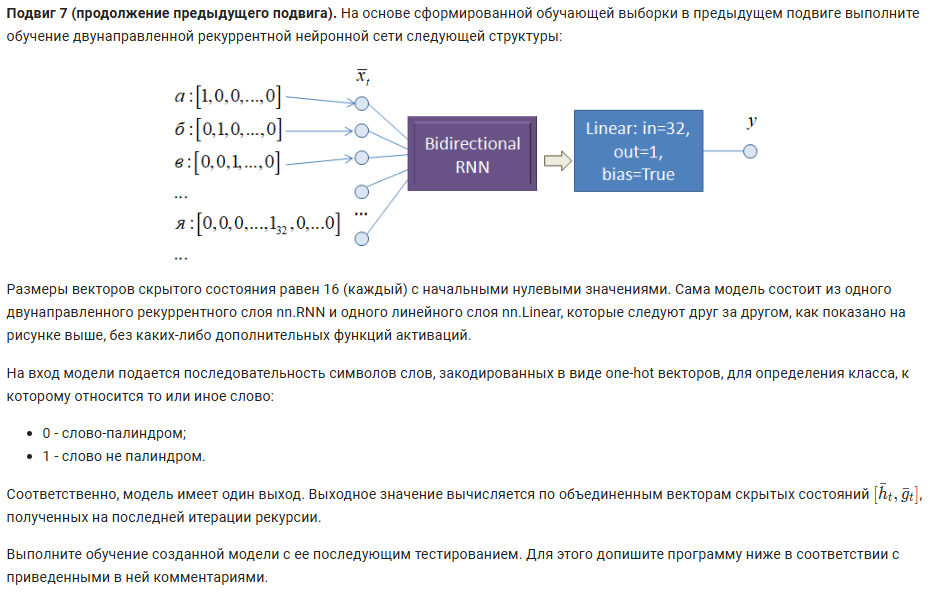

In [251]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim

# сюда копируйте класс WordsDataset, созданный на предыдущем занятии
class WordsDataset(data.Dataset):
    def __init__(self, batch_size=8):
        super().__init__()
        self.batch_size = batch_size

        data = [(word, 0) for word in _global_words_0] + [(word, 1) for word in _global_words_1]
        data.sort(key=lambda x: len(x[0]))

        self.batches = len(data) // self.batch_size

        self.words = [item[0] for item in data]
        self.labels = torch.tensor([item[1] for item in data], dtype=torch.float32)

        _text = "".join(_global_words_0 + _global_words_1).lower()
        self.alphabet = set(_text) # набор символов
        self.int_to_alpha = dict(enumerate(sorted(self.alphabet))) # число в символ
        self.zero_symbol = "@"
        
        self.int_to_alpha[len(self.int_to_alpha)] = self.zero_symbol # вводим вспомогательный символ
        self.alpha_to_int = {b: a for a, b in self.int_to_alpha.items()} # символ в число

        self.onehot = torch.eye(len(self.alphabet))
        self.onehot = torch.nn.functional.pad(self.onehot, (0, 0, 0, 1)) # последняя строка теперь нулевой вектор
    

    def __getitem__(self, item): # формирование и возвращение батча данных по индексу item
        
        start = item * self.batch_size
        end = start + self.batch_size

        batch = self.words[start: end]
        batch_longest_word_length = len(batch[-1])
        one_hot_words = []
        
        for word in batch:
            word += (batch_longest_word_length - len(word)) * self.zero_symbol
            one_hot_word = [self.onehot[self.alpha_to_int[letter]] for letter in word]
            one_hot_words.append(torch.stack(one_hot_word, dim=0))
            
        one_hot_words = torch.stack(one_hot_words)

        return one_hot_words, self.labels[start: end]


    def __len__(self): # возврат размер обучающей выборки в батчах
        
        return self.batches + bool(len(self.words)%self.batch_size)

# здесь объявляйте класс модели
class MyNet(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, bidirectional=True, batch_first=True)
        self.linear = nn.Linear(32, 1, bias=True)

    def forward(self, x):
        # print('x.shape', x.shape)
        x = x.squeeze(0)
        # print('x.shape', x.shape)
        y, h = self.rnn(x)
        h = torch.cat([h[0, :, :], h[1, :, :]], dim=1)
        out = self.linear(h).squeeze(1)
        return out
        


d_train = WordsDataset()
train_data = data.DataLoader(d_train, batch_size=1, shuffle=True)

model = MyNet(input_size=len(d_train.alphabet), hidden_size=16) # создание модели с числом входов, равным размеру словаря (размеру one-hot векторов)

optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.001) # оптимизатор Adam с шагом обучения 0.01 и параметром weight_decay=0.001
loss_func = nn.BCEWithLogitsLoss() # бинарная кросс-энтропия BCEWithLogitsLoss

epochs = 2 # число эпох обучения (в реальности нужно от 100 и более)
# переведите модель в режим обучения
model.train()

for _e in range(epochs):
    for x_train, y_train in train_data:
        # print('x_train.shape', x_train.shape)
        predict = model(x_train) # вычислите прогноз модели для x_train
        loss = loss_func(predict, y_train.squeeze(0)) # вычислите потери для predict и y_train
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # выполните один шаг обучения (градиентного спуска)

# переведите модель в режим эксплуатации
model.eval()
Q = 0 # начальное значение доли верных классификаций
for x_train, y_train in train_data:
    with torch.no_grad():
        # print(y_train.shape)
        p = model(x_train).sigmoid() # вычислите прогноз модели для x_train
        p = torch.tensor(p>0.5, dtype=torch.float32)
        # print(y_train.squeeze(0), p)
        y_train = y_train.squeeze(0)
        p = torch.sum(p==y_train).item() / y_train.shape[0]
        # print(p)
        Q += p # вычислите долю верных классификаций для p и y_train

Q = Q / len(d_train) # усреднение по всем батчам
Q

C:\Users\z.kuznetsov\AppData\Local\Temp\ipykernel_15636\4261058656.py:103: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  p = torch.tensor(p>0.5, dtype=torch.float32)


0.905

In [254]:
p = torch.tensor([-1., 2., 4.]).sigmoid()
# p = torch.tensor(p>0.5, dtype=torch.float32)
p

tensor([0.2689, 0.8808, 0.9820])

In [255]:
p = torch.tensor([-1., 2., 4.]).softmax(dim=0)
# p = torch.tensor(p>0.5, dtype=torch.float32)
p

tensor([0.0059, 0.1185, 0.8756])